# QAOA：把图分成两组

MaxCut 希望让尽可能多的边跨越两个分组。本例有四个节点组成的环，最佳分组可以切开全部四条边。QAOA 用可训练的量子电路提高好分组的出现概率。

In [2]:
from qutai import nn, quantum, visualization

device = "apple"

## 1. 定义问题

`maxcut()` 将“切开一条边”记为成本 −1；最小化成本就相当于最大化切开的边数。

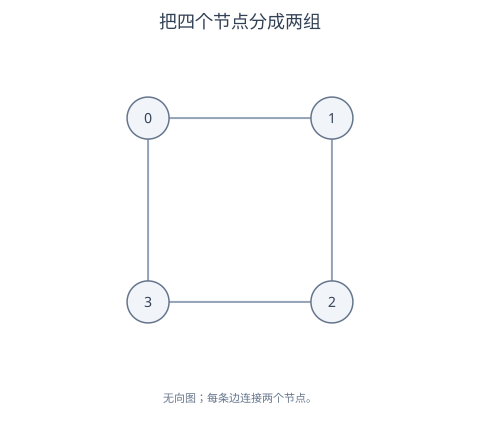

In [3]:
edges = [(0, 1), (1, 2), (2, 3), (3, 0)]
model = quantum.QAOA(4, quantum.maxcut(edges), depth=1).to(device)
optimizer = nn.AdamW(model, learning_rate=0.05)
visualization.Graph(range(4), edges, title="把四个节点分成两组")

## 2. 优化电路

每层交替执行成本演化与混合演化，角度由优化器调整。和 VQE 一样，这里没有数据集，只优化一个问题的期望成本。

当前期望切边数： 2.99521541595459


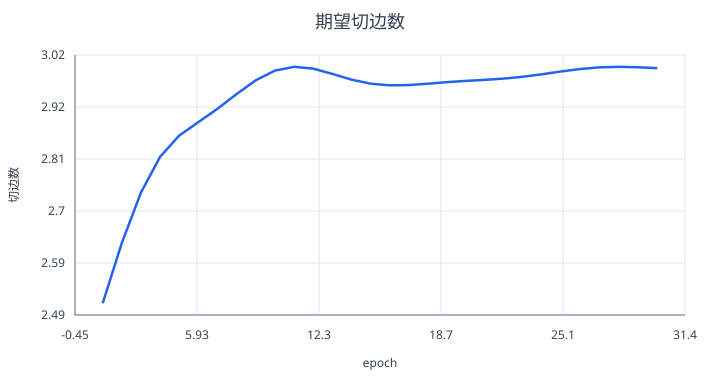

In [4]:
epochs = 30
cuts = []
# 没有数据集：每轮直接优化一次当前电路的目标值。
for epoch in range(epochs):
    optimizer.zero_grad()
    loss = model.expectation()
    loss.backward()
    optimizer.step()
    cuts.append(-loss.item())
print("当前期望切边数：", -model.expectation().item())
visualization.Plot(title="期望切边数", xlabel="epoch", ylabel="切边数").line(range(1, epochs + 1), cuts)

## 3. 读取分组结果

位串中的 0 和 1 表示两个分组，例如 `0101` 可以切开四条边。概率较大表示更容易被采到；一层 QAOA 不保证只生成最佳分组。

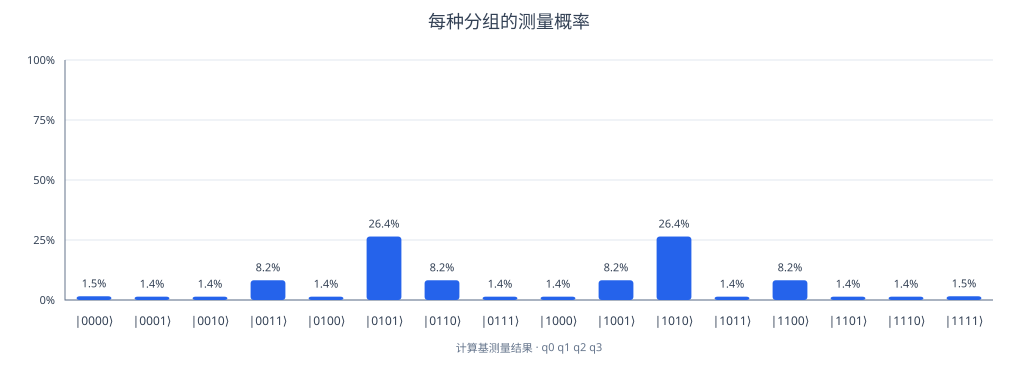

In [5]:
state = model.run()
visualization.Probabilities(state, title="每种分组的测量概率")

采到的分组： 0101


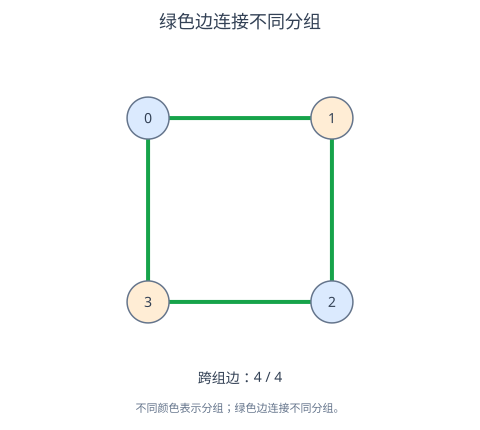

In [6]:
bits = state.sample()[0]
print("采到的分组：", bits)
visualization.Graph(range(4), edges, groups={wire: int(bit) for wire, bit in enumerate(bits)}, title="绿色边连接不同分组")